# Introduction to Graphons

A hands-on companion notebook to the *Introduction to Graphons* talk.

We'll cover:
- what a graphon is
- how to sample a random graph from a graphon
- a few standard graphon examples (Erd&#337;s&ndash;R&eacute;nyi, stochastic block model, ring)
- three ways to combine two graphons into one: **simple (convex) addition**, **disjoint union**, and **disjoint union with a join**

All of the underlying functions live in `graphons.py`, in the src folder; Colab downloads it automatically. 

In [ ]:
import sys
# On Colab: install igraph and download graphons.py. Locally: read it from ../src.
if "google.colab" in sys.modules:
    !pip install -q python-igraph
    BASE = "https://raw.githubusercontent.com/sevvandi/sevvandi.github.io/BRANCH/assets/notebooks/NeurIPS_2026/src"
    !wget -q {BASE}/graphons.py
else:
    sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt
import igraph as ig


from graphons import (
    ring_graphon,
    sbm_graphon,
    graphon_one_to_N,
    sample_graph_from_graphon,
    plot_graphon,
    arrange_matrix,
    graphon_addition,
    disjoint_graphon_addition,
    disjoint_graphon_addition_with_join,
)

%matplotlib inline
np.random.seed(0)

## What is a graphon?

A **graphon** is a symmetric, measurable function traditionallyl defined on a unit square. 

$$W : [0,1]^2 \to [0,1]$$

Think of it as a continuum version of an adjacency matrix,that is, if you map the adjacency matrix to a unit square and then take the limit, you end up with a graphon. Instead of a finite $n \times n$ binary matrix, $W$ assigns an *edge probability* $W(x,y)$ to every pair of points $x, y \in [0,1]$.

We can visualize a graphon directly as a heatmap (dark = high edge probability). Here are a few examples, evaluated on a $100 \times 100$ grid:

In [ ]:
import importlib
import graphons

from graphons import (
    ring_graphon,
    sbm_graphon,
    graphon_one_to_N,
    sample_graph_from_graphon,
    plot_graphon,
    arrange_matrix,
    graphon_addition,
    disjoint_graphon_addition,
    disjoint_graphon_addition_with_join,
)

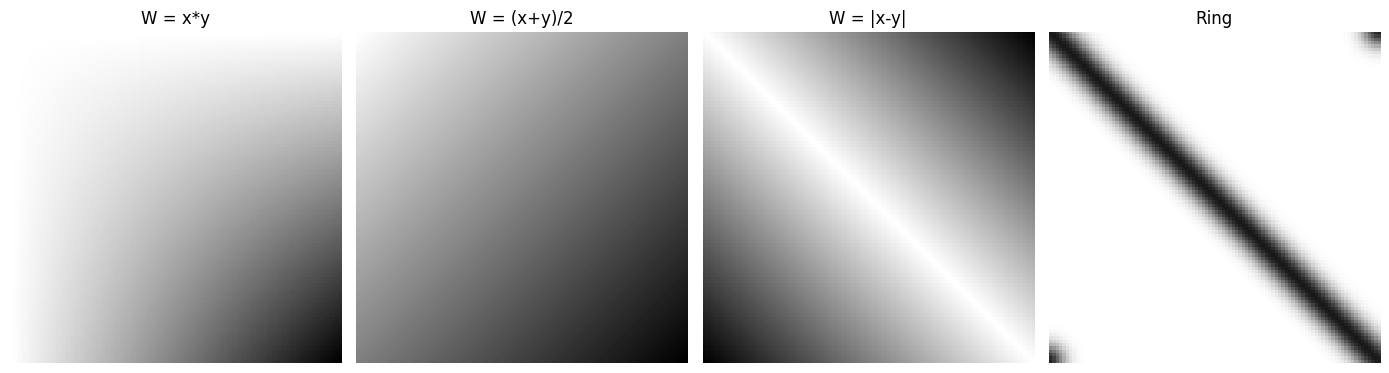

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
items = [1, 4, 10, 14]
titles = ["W = x*y", "W = (x+y)/2", "W = |x-y|", "Ring"]

for ax, item, title in zip(axes, items, titles):
    W = graphon_one_to_N(item=item, n=100, alpha=0.05)
    ax.imshow(W, cmap="gray_r", vmin=0, vmax=1, origin="upper")
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

## Sampling a graph from a graphon

Given a graphon $W$, `sample_graph_from_graphon(W, n)`:

1. draws $n$ points $u_1, \dots, u_n$ uniformly from $[0,1]$ (one per vertex),
2. maps each point onto the graphon's grid,
3. connects vertices $i$ and $j$ with probability $W(u_i, u_j)$.

As $n \to \infty$, graphs sampled this way converge to $W$ &mdash; this is the sense in which a graphon is a "limit object" for a sequence of graphs. Below, we sample increasingly large graphs from the same graphon and plot them.

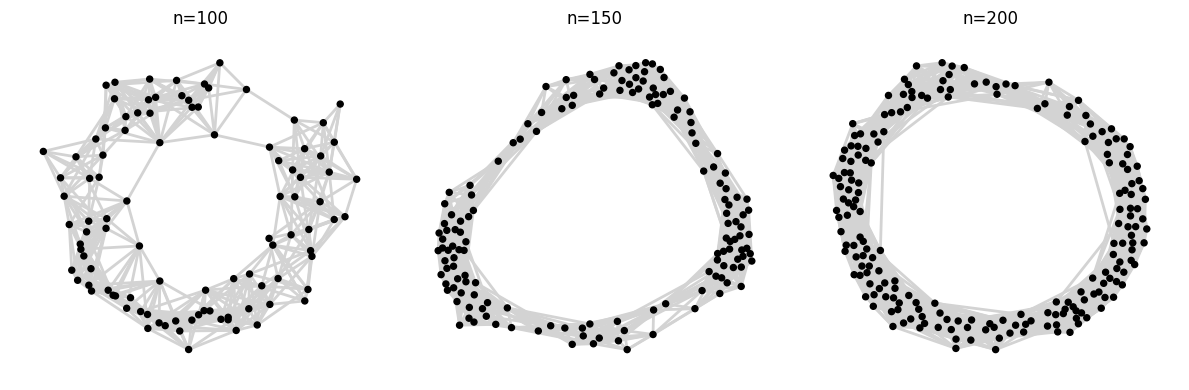

In [23]:
def plot_sampled_graphs(W, ns, figsize=(12, 4)):
    """Sample a graph at each size in `ns` from graphon W and plot them side by side."""
    fig, axes = plt.subplots(1, len(ns), figsize=figsize)
    if len(ns) == 1:
        axes = [axes]
    for ax, n in zip(axes, ns):
        adj = sample_graph_from_graphon(W, n)
        g = ig.Graph.Adjacency((adj > 0).tolist(), mode="undirected")
        ig.plot(g, target=ax, vertex_size=6, vertex_color="black", edge_color="lightgray")
        ax.set_title(f"n={n}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


W_demo = graphon_one_to_N(item=14, n=100)
plot_sampled_graphs(W_demo, ns=[100, 150, 200])

## The simplest graphon: a constant

Setting $W(x,y) = p$ everywhere recovers the classic **Erd&#337;s&ndash;R&eacute;nyi** model $G(n,p)$. For this model, the edge probability is $p$ for any possible edge, regardless of vertex identity.

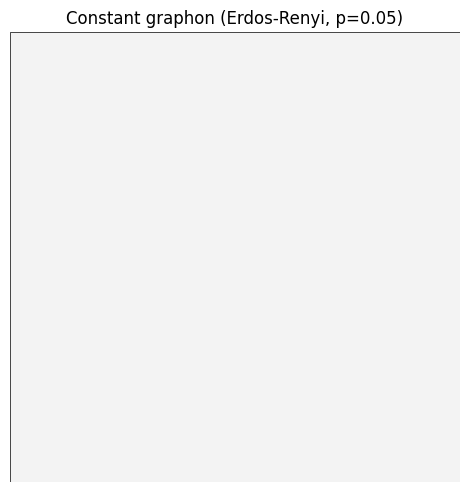

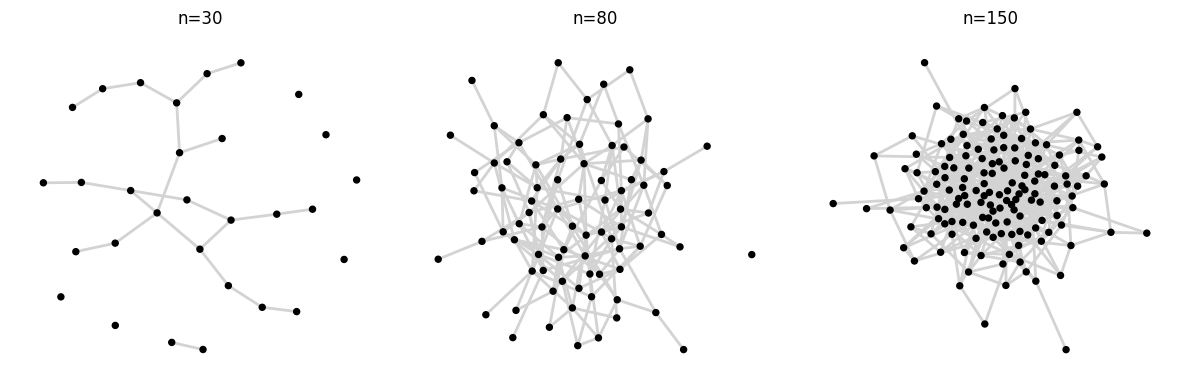

In [26]:
W_er = np.full((100, 100), 0.05)

fig, ax = plot_graphon(W_er)
ax.set_title("Constant graphon (Erdos-Renyi, p=0.05)")
plt.show()

plot_sampled_graphs(W_er, ns=[30, 80, 150])

## Stochastic block model (SBM) graphon



An SBM graphon is piecewise constant: vertices are split into $k$ groups, and the edge probability only depends on which groups the two endpoints belong to. It is a simple way to generate graphs with community structure. Vertices within same block connect with a higher probability, while vertices in different blocks connect with a lower probability making it a common tool for studying clustering and community detection,

The funcion `sbm_graphon(mat, n)` expands a small $k \times k$ probability matrix into a full $n \times n$ graphon by repeating each entry over a block.

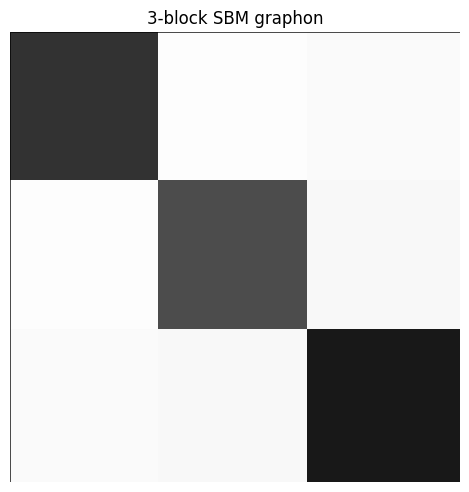

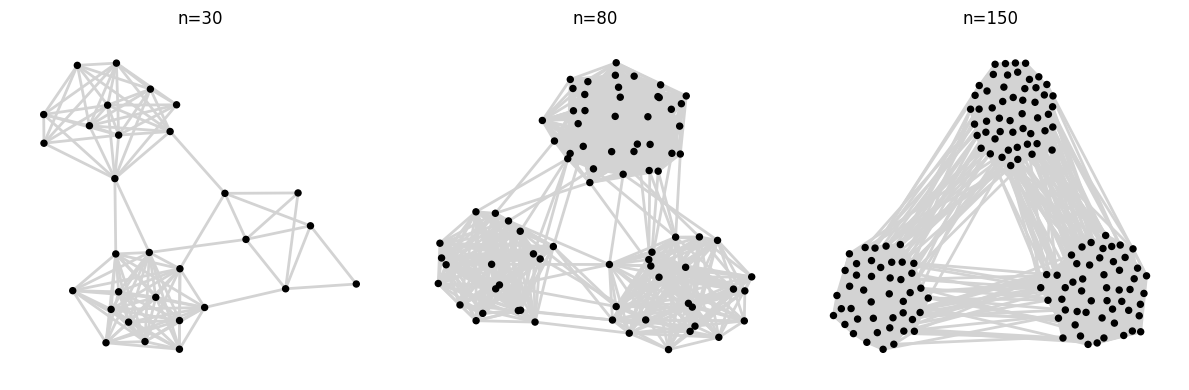

In [31]:
block_probs = np.array([
    [0.8, 0.01, 0.02],
    [0.01, 0.7, 0.03],
    [0.02, 0.03, 0.9]
])

W_sbm = sbm_graphon(block_probs, 100)

fig, ax = plot_graphon(W_sbm)
ax.set_title("3-block SBM graphon")
plt.show()

plot_sampled_graphs(W_sbm, ns=[30, 80, 150])

## Ring graphon

`ring_graphon(n, alpha)` builds a graphon supported near a diagonal "ring" (wrapping around at the edges), controlled by a bandwidth parameter `alpha`. Graphs sampled from it have a ring type structure.

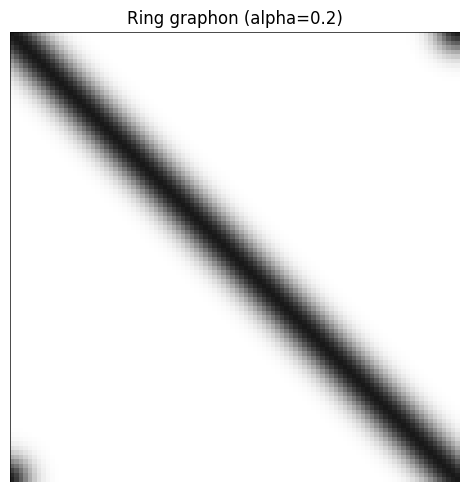

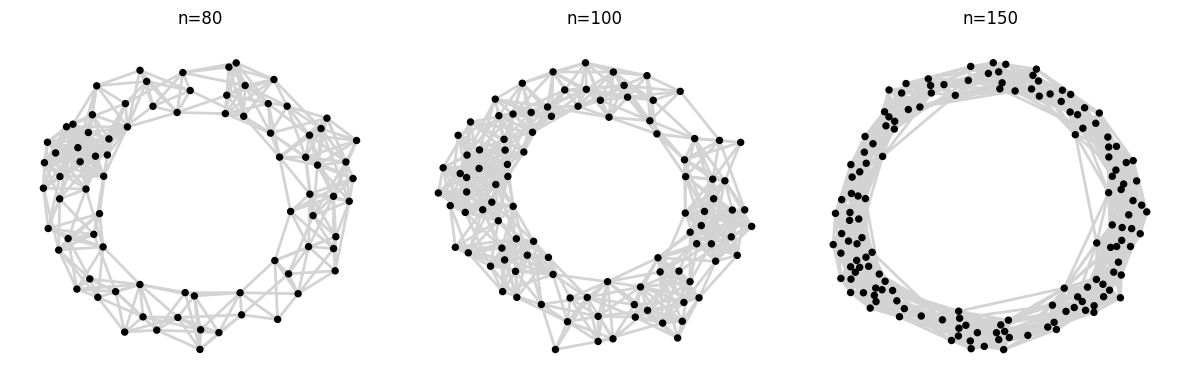

In [30]:
W_ring = ring_graphon(100, alpha=0.05)

fig, ax = plot_graphon(W_ring)
ax.set_title("Ring graphon (alpha=0.2)")
plt.show()

plot_sampled_graphs(W_ring, ns=[80, 100, 150])

## Combining two graphons

Given two graphons $W_1$ and $W_2$, there are multiple ways to combine them into a single graphon. We'll look at three:

1. **Convex addition** &mdash; scale and add $W_1$ and $W_2$ pointwise as functions on the unit square. Denoted by $\alpha W_1 + (1-\alpha) W_2$.
2. **Disjoint union** &mdash; scale $W_1$ to a square of size $\alpha$ and $W_2$ to  a square of size $(1-\alpha)$ and place them in $[0,\alpha]^2$ and $[\alpha, 1]^2$ respectively. Denoted by $\alpha W_1 \oplus (1-\alpha) W_2$
3. **Disjoint union with a join** &mdash; disjoint union graphon as above but *with* edges between the two parts, determined by $J:[0,1]^2 \to [0,1]$.

Each of these has a different effect on graphs sampled from the result, as we'll see below.

### 1. Simple (convex) addition

`graphon_addition(W1, W2, alpha)` returns $\alpha W_1 + (1-\alpha) W_2$, evaluated pointwise on a shared grid. The two graphons are *overlaid* &mdash; every pair of vertices gets a blended edge probability.

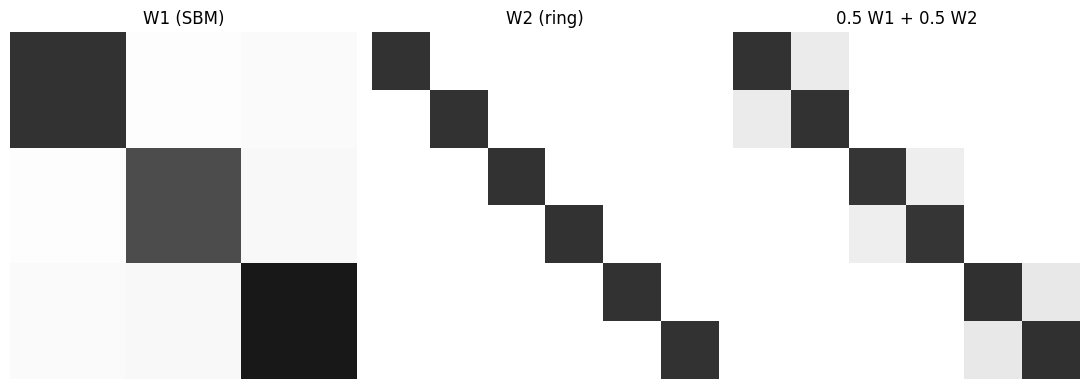

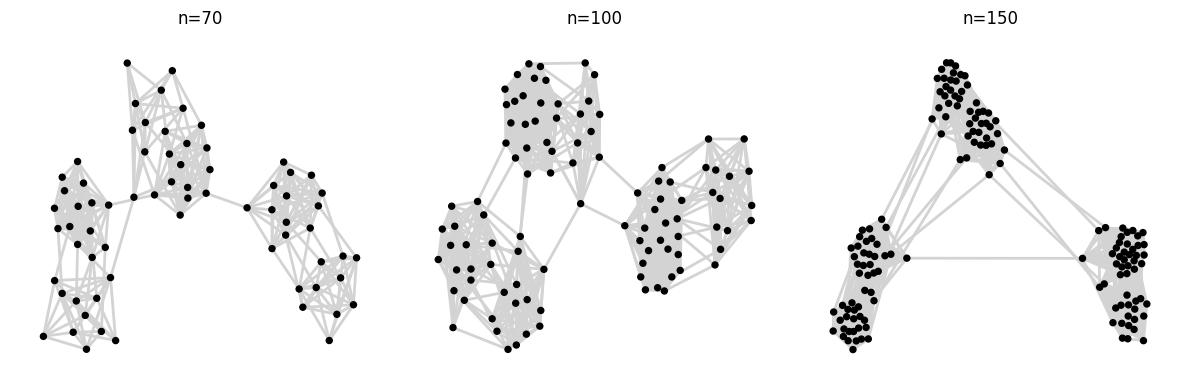

In [39]:
W1 = sbm_graphon(block_probs, 60)
W2 = sbm_graphon(np.diag(np.full(6, 0.8)), 60)
W_add = graphon_addition(W1, W2, alpha=0.1)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for ax, W, title in zip(axes, [W1, W2, W_add], ["W1 (SBM)", "W2 (ring)", "0.5 W1 + 0.5 W2"]):
    ax.imshow(W, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

plot_sampled_graphs(W_add, ns=[70, 100, 150])

### 2. Disjoint union

`disjoint_graphon_addition(W1, W2, alpha)` places $W_1$ and $W_2$ as two blocks along the diagonal, sized $\alpha$ and $1-\alpha$ of the total, with the off-diagonal blocks set to **0**. Graphs sampled from this graphon look like two separate, disconnected components &mdash; one shaped like $W_1$'s graphs, one like $W_2$'s.

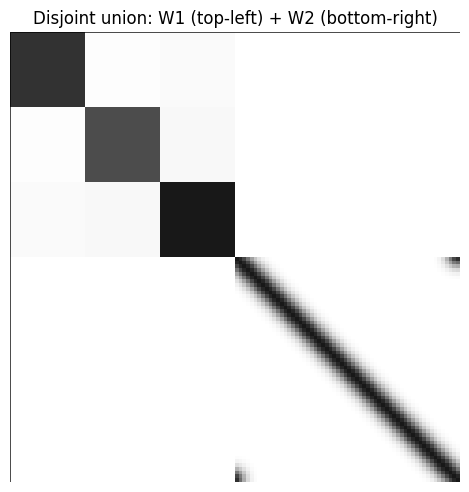

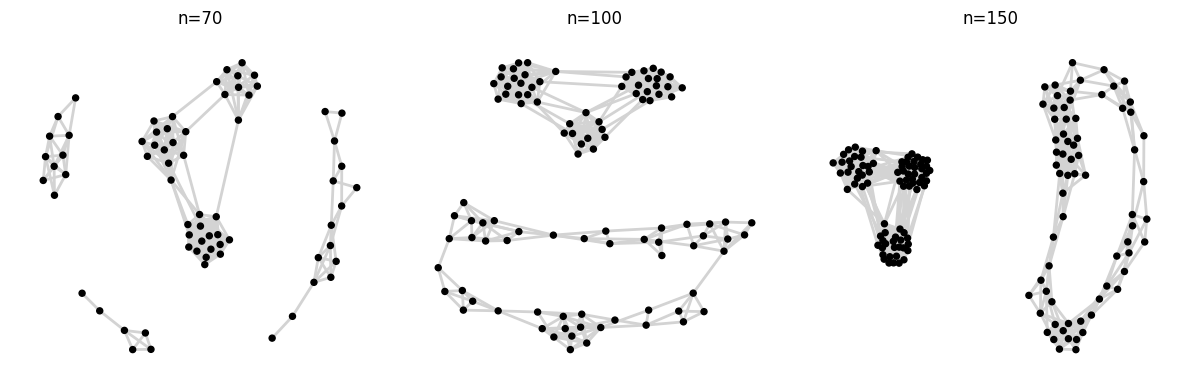

In [41]:
W2 = ring_graphon(60, alpha=0.05)
W_disjoint = disjoint_graphon_addition(W1, W2, alpha=0.5)

fig, ax = plot_graphon(W_disjoint)
ax.set_title("Disjoint union: W1 (top-left) + W2 (bottom-right)")
plt.show()

plot_sampled_graphs(W_disjoint, ns=[70, 100, 150])

### 3. Disjoint union with a join

`disjoint_graphon_addition_with_join(W1, W2, alpha, p)` uses the same block layout, but fills the off-diagonal blocks with another block $J$ instead. Note that $J$ doesn't need to be symmetric as the transpose is repeated at the other diagonal block. $J$ connects the two parts &mdash; every pair of vertices from different parts now has edge probability given by $J$. Setting $J=1$ recovers a well-studied graph-theoretic **join** (every vertex in part 1 connects to every vertex in part 2); $p=0$ recovers plain disjoint union.

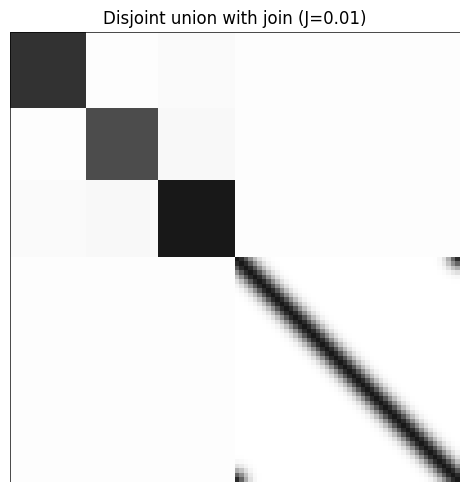

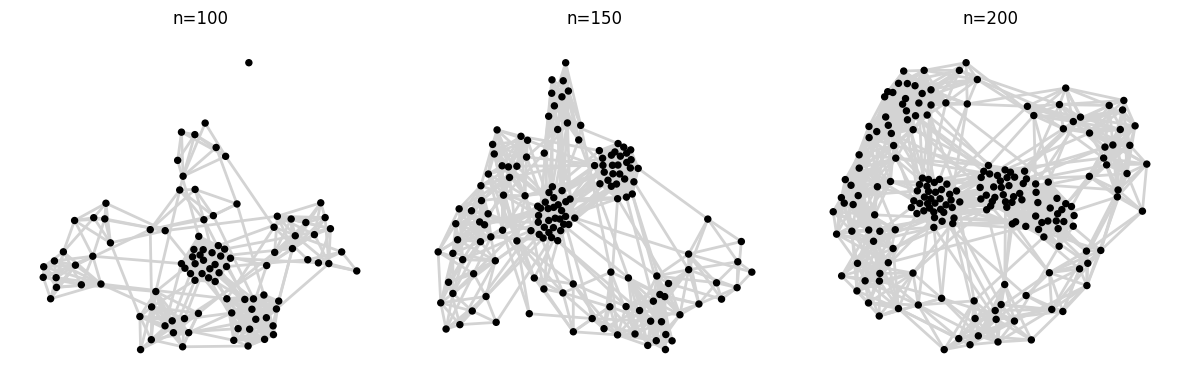

In [63]:
W1 = sbm_graphon(block_probs, 100)
W2 = ring_graphon(100, alpha=0.05)
W3 = np.full((100, 100), 0.01)
W_join = disjoint_graphon_addition_with_join(W1, W2, W3, alpha=0.5)

fig, ax = plot_graphon(W_join)
ax.set_title("Disjoint union with join (J=0.01)")
plt.show()

plot_sampled_graphs(W_join, ns=[100, 150, 200])

## Recap

| Operation | Function | Off-diagonal blocks | Sampled graphs look like |
|---|---|---|---|
| Convex addition | `graphon_addition` | Not applicable, as simple addition | one blended graph |
| Disjoint union | `disjoint_graphon_addition` | 0 | two separate components |
| Disjoint union with join | `disjoint_graphon_addition_with_join` | function/graphon $J$ | two parts connected by cross-edges |

Try changing `alpha` (the relative size of the two parts) and `J` (the joining function/graphon) above, or swap in a different pair of graphons from `graphon_one_to_N`, to build intuition for how each operation reshapes the sampled graphs.